## Test de trajectoires des navires de pêche présents dans le parc 

Hypothèse testée: Des bateaux de pêche éteignent leur AIS dans le parc?

Type de bateaux: pêche palangrière

In [53]:
import os
import numpy as np

import pandas as pd
import geopandas as gpd

import datetime
import time

import matplotlib.pyplot as plt
import seaborn as sns
import folium

In [3]:
# load the data path
os.chdir('C:/Users/anael/Documents/PNMCCA_Marbec_2026/traj_bateaux_PNMCCA/')

## Trajectoires GFW
### bateaux identifié sur GFW directement
Bateaux de pêche (palangriers) qui font au moins un passage à un moment t dans le parc marin (pêche ou non).

- Italia II > 2024
- Madonna del Carmine > 2022-2026
- Madonna di Fatima > 2023
- Ammiraglia > 2023
- ct2895 > 2022

### Bateaux ajouté à partir des données AIS 2025 fournit par le parc
2 bateaux ajoutés (palangriers). 

- Pablo I > 2024-2026
- Feli > 2025-2026

Madonna del Carmine bien pésent dans leur données aussi. 6 bateaux de pêches présents dans les données AIS du parc mais pas inclus ici car pas palangriers (chalutier ou senner), traverse juste une ou deux fois le parc, ou mauvaise classif (bateaux de loisir, fishery research vessel).

In [4]:
# navires trouvé à partir de GFW uniquement 
ammiraglia = pd.read_csv('./raw_traj_GFW/ammiraglia-2023-2024.csv')
ct2895 = pd.read_csv('./raw_traj_GFW/ct2895-2022.csv')
italiaII = pd.read_csv('./raw_traj_GFW/italiaII-2023.csv')
madonnadelcarmine = pd.read_csv('./raw_traj_GFW/madonnadelcarmine-2022-2026.csv')
madonnadifatima = pd.read_csv('./raw_traj_GFW/madonnadifatima-2023.csv')

# 2 navires ajourter suite grâce aux détections AIS fournit par le parc + traj de GFW
feli = pd.read_csv('./raw_traj_GFW/feli-2025-2026.csv')
pabloI = pd.read_csv('./raw_traj_GFW/pabloI-2024-2026.csv')

In [5]:
ais_data_list = [ammiraglia, ct2895, italiaII, madonnadelcarmine, madonnadifatima, feli, pabloI]

## Tester sur ces bateaux l'hypothèse de coupure d'AIS 
(comparer à ce que fait GFW (ont aussi des critères définissant des event de coupure d'AIS, mais aucun bateau de cette liste n'a de tel detections dans GFW). 

In [6]:
ais_data_list[0]

,lon,lat,course,timestamp,speed,depth,seg_id
0,15.800467,38.315630,319.799988,2023-01-03T03:55:48.000Z,7.8,-414,247133620-2023-01-03T03:55:48.000000Z-1
1,15.747247,38.355190,308.799988,2023-01-03T04:19:36.000Z,8.7,-358,247133620-2023-01-03T03:55:48.000000Z-1
2,15.719147,38.382538,320.000000,2023-01-03T04:34:37.000Z,8.3,-438,247133620-2023-01-03T03:55:48.000000Z-1
3,15.687755,38.407688,316.299988,2023-01-03T04:49:47.000Z,8.2,-459,247133620-2023-01-03T03:55:48.000000Z-1
4,15.620213,38.445623,272.700012,2023-01-03T05:37:56.000Z,1.6,-627,247133620-2023-01-03T03:55:48.000000Z-1
...,...,...,...,...,...,...,...
7983,15.722483,38.391087,149.699997,2023-12-29T15:00:41.000Z,6.1,-440,247133620-2023-12-27T03:55:41.000000Z-1
7984,15.740368,38.370843,142.300003,2023-12-29T15:14:32.000Z,8.0,-363,247133620-2023-12-27T03:55:41.000000Z-1
7985,15.791050,38.319625,141.000000,2023-12-29T15:41:02.000Z,9.0,-436,247133620-2023-12-27T03:55:41.000000Z-1
7986,15.803427,38.308580,135.000000,2023-12-29T15:47:11.000Z,8.7,-362,247133620-2023-12-27T03:55:41.000000Z-1


In [9]:
for i in np.arange(7):
    df = ais_data_list[i]
    df.loc[: ,'timestamp'] = pd.to_datetime(df.timestamp)

In [10]:
ais_data_list[i]

,lon,lat,course,timestamp,speed,depth,seg_id
0,13.541685,38.087927,167.800003,2024-05-08 13:25:08+00:00,4.2,-9.500000,247143810-2024-05-08T13:25:08.000000Z-1
1,13.552322,38.083573,101.300003,2024-05-08 13:32:17+00:00,6.1,-39.666667,247143810-2024-05-08T13:25:08.000000Z-1
2,13.565988,38.080993,97.400002,2024-05-08 13:38:17+00:00,6.9,-63.500000,247143810-2024-05-08T13:25:08.000000Z-1
3,13.579802,38.080855,81.900002,2024-05-08 13:43:46+00:00,7.2,-82.833333,247143810-2024-05-08T13:25:08.000000Z-1
4,13.686030,38.092898,83.400002,2024-05-08 14:25:36+00:00,7.2,-424.000000,247143810-2024-05-08T13:25:08.000000Z-1
...,...,...,...,...,...,...,...
12916,13.501668,38.145083,135.600006,2026-09-15 08:28:10+00:00,7.1,-366.666667,247143810-2026-09-12T13:45:44.000000Z-1
12917,13.520692,38.130000,133.300003,2026-09-15 08:39:10+00:00,6.6,-150.333333,247143810-2026-09-12T13:45:44.000000Z-1
12918,13.534207,38.120457,133.899994,2026-09-15 08:46:00+00:00,8.2,-106.333333,247143810-2026-09-12T13:45:44.000000Z-1
12919,13.540905,38.111205,172.800003,2026-09-15 08:51:00+00:00,7.9,-66.750000,247143810-2026-09-12T13:45:44.000000Z-1


In [13]:
# fonction qui calcule l'intervalle de temps entre deux timestamp
def Tdiff(data_ais):    
    #create new columns shifting the timestamp_formated up and down by one
    data_ais['timestamp_down'] = data_ais['timestamp'].shift(1, axis=0)
    data_ais['timestamp_up'] = data_ais['timestamp'].shift(-1, axis=0)
    
    # calculate the mean time based on the new columns
    data_ais['T'] = (data_ais['timestamp_up'] - data_ais['timestamp_down'])/2
    
    #drop the column created to keep the df clean
    data_ais = data_ais.drop(['timestamp_down', 'timestamp_up'], axis=1)

    return data_ais

In [38]:
for i in np.arange(7):
    df = ais_data_list[i]
    df = Tdiff(df)
    df['T'] = pd.to_timedelta(df['T'])
    df['T_hour'] = df['T'].dt.total_seconds() / 3600 #transform T in a number of hour
    ais_data_list[i] = df

<Axes: >

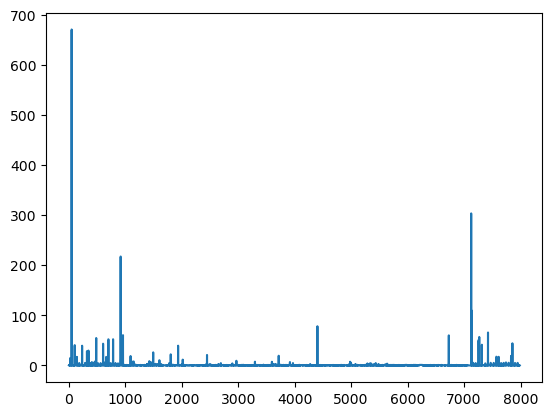

In [39]:
ais_data_list[0]['T_hour'].plot()

In [65]:
ais_data_list[0]

,lon,lat,course,timestamp,speed,depth,seg_id,T,T_hour
0,15.800467,38.315630,319.799988,2023-01-03 03:55:48+00:00,7.8,-414,247133620-2023-01-03T03:55:48.000000Z-1,NaT,NaN
1,15.747247,38.355190,308.799988,2023-01-03 04:19:36+00:00,8.7,-358,247133620-2023-01-03T03:55:48.000000Z-1,0 days 00:19:24.500000,0.323472
2,15.719147,38.382538,320.000000,2023-01-03 04:34:37+00:00,8.3,-438,247133620-2023-01-03T03:55:48.000000Z-1,0 days 00:15:05.500000,0.251528
3,15.687755,38.407688,316.299988,2023-01-03 04:49:47+00:00,8.2,-459,247133620-2023-01-03T03:55:48.000000Z-1,0 days 00:31:39.500000,0.527639
4,15.620213,38.445623,272.700012,2023-01-03 05:37:56+00:00,1.6,-627,247133620-2023-01-03T03:55:48.000000Z-1,0 days 00:38:15.500000,0.637639
...,...,...,...,...,...,...,...,...,...
7983,15.722483,38.391087,149.699997,2023-12-29 15:00:41+00:00,6.1,-440,247133620-2023-12-27T03:55:41.000000Z-1,0 days 00:19:05.500000,0.318194
7984,15.740368,38.370843,142.300003,2023-12-29 15:14:32+00:00,8.0,-363,247133620-2023-12-27T03:55:41.000000Z-1,0 days 00:20:10.500000,0.336250
7985,15.791050,38.319625,141.000000,2023-12-29 15:41:02+00:00,9.0,-436,247133620-2023-12-27T03:55:41.000000Z-1,0 days 00:16:19.500000,0.272083
7986,15.803427,38.308580,135.000000,2023-12-29 15:47:11+00:00,8.7,-362,247133620-2023-12-27T03:55:41.000000Z-1,0 days 00:06:36,0.110000


In [68]:
# selectionné les lignes où l'écart des timestamp est supérieur à 24h / 48h.
# Mapper les deux points AIS en question (permet de voir si le bateau est au port ou en mer)  

ais_ecarts_list = []

for i in range(7):
    values_list = []
    df = ais_data_list[i].copy()
    mask = df['T_hour'] > 24 
    indices = df.index[mask]# Indices des lignes qui remplissent la condition

    for idx in indices:     
        pos = df.index.get_loc(idx)# Position de la ligne dans le DataFrame
        if pos > 0:
            T_hour = df.iloc[pos]['T_hour']
            timestamp_A = df.iloc[pos-1]['timestamp']
            timestamp_B = df.iloc[pos]['timestamp']
            
            lon_A = df.iloc[pos]['lon']
            lat_A = df.iloc[pos]['lat']
            course_A = df.iloc[pos]['course']
            speed_A = df.iloc[pos]['speed']
            depth_A = df.iloc[pos]['depth']

            lon_B = df.iloc[pos-1]['lon']
            lat_B = df.iloc[pos-1]['lat']
            course_B = df.iloc[pos-1]['course']
            speed_B = df.iloc[pos-1]['speed']
            depth_B = df.iloc[pos-1]['depth']

            values_list.append((T_hour, timestamp_A, timestamp_B, 
                                lon_A, lat_A, course_A, speed_A, depth_A,
                               lon_B, lat_B, course_B, speed_B, depth_B,))
    ais_ecarts= pd.DataFrame(values_list, columns=['T_hour', 'timestamp_A', 'timestamp_B', 
                                                   'lon_A', 'lat_A', 'course_A', 'speed_A', 'depth_A',
                                                  'lon_B', 'lat_B', 'course_B', 'speed_B', 'depth_B']) # df 
    ais_ecarts_list.append(ais_ecarts)

In [71]:
ais_ecarts_list[1]

,T_hour,timestamp_A,timestamp_B,lon_A,lat_A,course_A,speed_A,depth_A,lon_B,lat_B,course_B,speed_B,depth_B
0,275.053611,2022-05-28 23:29:12+00:00,2022-05-28 23:45:33+00:00,15.210767,37.475802,342.700012,7.2,-755,15.223978,37.444193,337.000000,7.4,-844
1,274.956250,2022-05-28 23:45:33+00:00,2022-06-20 21:35:38+00:00,10.594747,42.779035,330.800000,9.0,-89,15.210767,37.475802,342.700012,7.2,-755
2,25.417361,2022-06-26 05:25:04+00:00,2022-06-26 05:39:15+00:00,9.444563,43.623672,97.800003,4.7,-659,9.420638,43.625765,86.900000,5.7,-718
3,25.709028,2022-06-26 05:39:15+00:00,2022-06-28 08:15:09+00:00,9.334072,43.654062,281.100000,3.3,-1144,9.444563,43.623672,97.800003,4.7,-659
4,297.635556,2022-06-29 16:30:27+00:00,2022-06-29 16:50:37+00:00,9.186342,43.446083,196.800000,5.6,-1346,9.200620,43.479777,192.100000,6.7,-1316
5,297.720556,2022-06-29 16:50:37+00:00,2022-07-24 11:46:43+00:00,10.304102,43.549982,NaN,0.0,2,9.186342,43.446083,196.800000,5.6,-1346
6,83.768889,2022-07-27 00:19:24+00:00,2022-07-27 00:50:53+00:00,9.259635,43.448607,61.599998,1.7,-895,9.249097,43.442845,98.699997,1.0,-1086
7,83.761111,2022-07-27 00:50:53+00:00,2022-08-02 23:51:40+00:00,10.153780,43.496832,262.000000,8.0,-51,9.259635,43.448607,61.599998,1.7,-895
8,44.868194,2022-08-03 01:57:15+00:00,2022-08-03 03:02:47+00:00,9.599208,43.550603,284.000000,8.2,-547,9.788033,43.523383,283.000000,7.4,-375
9,44.436111,2022-08-03 03:02:47+00:00,2022-08-06 19:41:26+00:00,8.685260,43.978003,55.099998,7.6,-1747,9.599208,43.550603,284.000000,8.2,-547


In [ ]:
# mapper les points avant/après
colors = ['orange', 'blue']

map = folium.Map(location=[ais_ecarts_list[1]['lat'].mean(), ais_ecarts_list[1]['lon'].mean()], zoom_start=2)

# add marckers for each encounters with the time of the encounter and the two vessels
for idx, row in ais_ecarts_list[1].iterrows():
    if row['transshipment_type'] == "transfering":
        i = 0
    else: 
        i = 1
    folium.Marker(
        location=[row['latitude'], row['longitude']],
        popup=row[['Support_vessel_IMO', 'vessel_transhipment', 'date_events', 'nature_of_activity']],  # Étiquette affichée sur le marqueur
        icon=folium.Icon(color=colors[i])
    ).add_to(map)

map

In [76]:
import re
from html import escape
import colorsys

In [81]:
map_list = []
for num_bateau in range(7): 
    df = ais_ecarts_list[num_bateau].copy()
    
    # Vérifier les coordonnées disponibles
    all_lats = pd.concat([df["lat_A"], df["lat_B"]]).dropna()
    all_lons = pd.concat([df["lon_A"], df["lon_B"]]).dropna()
    
    m = folium.Map(
        location=[all_lats.mean(), all_lons.mean()],
        zoom_start=12,
        tiles="OpenStreetMap"
    )
    
    # Générer une couleur distincte pour chaque paire
    def get_color(i):
        hue = (i * 0.61803398875) % 1
        r, g, b = colorsys.hsv_to_rgb(hue, 0.75, 0.85)
        return "#{:02x}{:02x}{:02x}".format(
            int(r * 255), int(g * 255), int(b * 255)
        )
    
    # Colonnes propres à chaque point
    cols_A = [c for c in df.columns if c.endswith("_A")]
    cols_B = [c for c in df.columns if c.endswith("_B")]
    
    def create_popup(row, cols, suffix, color):
        # T_hour est ajouté même s'il ne possède pas de suffixe
        html = f"""
        <div style="font-family: Arial; min-width: 220px;">
            <h4 style="color: {color}; margin-bottom: 8px;">
                Paire {row.name} — Point {suffix}
            </h4>
            <table style="border-collapse: collapse; width: 100%;">
        """
    
        # Afficher T_hour en premier
        fields = ["T_hour"] + [c for c in cols if c != "T_hour"]
    
        for col in fields:
            if col not in row.index:
                continue
    
            label = col[:-2] if col.endswith(("_A", "_B")) else col
            value = escape(str(row[col]))
    
            html += f"""
            <tr>
                <td style="padding: 4px; border-bottom: 1px solid #ddd;">
                    <b>{escape(label)}</b>
                </td>
                <td style="padding: 4px; border-bottom: 1px solid #ddd;">
                    {value}
                </td>
            </tr>
            """
    
        html += "</table></div>"
        return folium.Popup(html, max_width=400)
    
    # Ajouter les marqueurs avec des formes différentes pour A et B
    for i, (idx, row) in enumerate(df.iterrows()):
        color = get_color(i)
    
        # Point A : cercle
        if pd.notna(row["lat_A"]) and pd.notna(row["lon_A"]):
            folium.CircleMarker(
                location=[row["lat_A"], row["lon_A"]],
                radius=7,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.85,
                weight=2,
                tooltip=f"Paire {idx} — Point A | T_hour: {row['T_hour']}",
                popup=create_popup(row, cols_A, "A", color)
            ).add_to(m)
    
        # Point B : triangle
        if pd.notna(row["lat_B"]) and pd.notna(row["lon_B"]):
            folium.RegularPolygonMarker(
                location=[row["lat_B"], row["lon_B"]],
                number_of_sides=3,
                radius=9,
                rotation=0,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.85,
                tooltip=f"Paire {idx} — Point B | T_hour: {row['T_hour']}",
                popup=create_popup(row, cols_B, "B", color)
            ).add_to(m)
        # Relier les points A et B de chaque paire
        if (
            pd.notna(row["lat_A"]) and pd.notna(row["lon_A"])
            and pd.notna(row["lat_B"]) and pd.notna(row["lon_B"])
        ):
            folium.PolyLine(
                locations=[
                    [row["lat_A"], row["lon_A"]],
                    [row["lat_B"], row["lon_B"]]
                ],
                color=color,
                weight=2,
                opacity=0.7,
                tooltip=f"Paire {idx} — T_hour: {row['T_hour']}"
            ).add_to(m)
    # Adapter le cadrage à tous les points valides
    points = []
    for _, row in df.iterrows():
        for lat_col, lon_col in [
            ("lat_A", "lon_A"),
            ("lat_B", "lon_B")
        ]:
            if pd.notna(row[lat_col]) and pd.notna(row[lon_col]):
                points.append([row[lat_col], row[lon_col]])
    
    if points:
        m.fit_bounds(points)

    map_list.append(m)


# Resultats

Visualisation des cartes : 1 carte par navire, représentant les paires de points AIS successifs espacés de >24h.

🔵 Cercle = Point A : localisation du premier point de la paire.

🔷 Triangle = Point B : localisation du second point de la paire.

Ces deux points sont reliés par une ligne.
Chaque paire de points AIS ainsi définie est représentée d'une couleur différente.

<u>Informations interactives<u>

Survol d'un marqueur : affiche l'identifiant de la paire, le type de point (A ou B) et la valeur de T_hour qui est la durée entre les deux points AIS successifs.

Clic sur un marqueur : ouvre une fenêtre contenant les informations associées au point: date, coordonnées, cap, vitesse.

Survol d'une ligne : affiche l'identifiant de la paire et la valeur de T_hour.


In [ ]:
list_names = ["ammiraglia", "ct2895", "italiaII", "madonnadelcarmine", "madonnadifatima", "feli", "pabloI"]

In [89]:
print(list_names[0])
display(map_list[0])

ammiraglia


In [91]:
print(list_names[1])
display(map_list[1])

ct2895


In [92]:
print(list_names[2])
display(map_list[2])

italiaII


In [93]:
print(list_names[3])
display(map_list[3])

madonnadelcarmine


In [94]:
print(list_names[4])
display(map_list[4])

madonnadifatima


In [95]:
print(list_names[5])
display(map_list[5])

feli


In [90]:
print(list_names[6])
display(map_list[6])

pabloI


In [97]:
dossier = 'C:\\Users\\anael\\Documents\\PNMCCA_Marbec_2026'

map_list[0].save(os.path.join(dossier, "map_1.html"))
map_list[1].save(os.path.join(dossier, "map_2.html"))
map_list[2].save(os.path.join(dossier, "map_3.html"))
map_list[3].save(os.path.join(dossier, "map_4.html"))
map_list[4].save(os.path.join(dossier, "map_5.html"))
map_list[5].save(os.path.join(dossier, "map_6.html"))
map_list[6].save(os.path.join(dossier, "map_7.html"))